# Módulo 4: roles de jugadores (clustering)

**Preguntas:**
- **D.** Entre jugadores de rotación, ¿hay grupos naturales de estilo de juego? ¿Cuántos? ¿Se parecen a las 5 posiciones clásicas?
- **Validez.** ¿Esos grupos son reales o un artefacto de k-means (que siempre devuelve k grupos)?

**Diseño (decidido antes de ver los datos):**
- Jugadores con ≥ 1000 minutos en 2025-26 (279). Comparación con 2024-25.
- 16 variables que describen *cómo* juega, no qué tan bien: por 100 posesiones (tiros, triples, libres, rebotes ofensivos y defensivos, asistencias, pérdidas, robos, tapones, faltas), proporción de tiros por zona (aro, pintura, media distancia, triple de esquina) y USG% y TS%. Todas estandarizadas (z-score).
- k-means con k de 2 a 10.
- Tres pruebas de realidad por cada k: **silueta contra un nulo** (columnas barajadas: mismas distribuciones, sin relación entre variables), **estabilidad** al remuestrear jugadores (índice de Rand ajustado, ARI) y **acuerdo con la temporada anterior**. Más: ¿cambia el resultado al quitar bloques de variables?

**Mi hipótesis previa:** ninguna ("sin intuición, corre"). La referencia es el nulo: "sin estructura".

Para reproducir: `python -m uv run jupyter lab`; los datos salen de la caché local.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.analysis.roles import (
    cluster_profile,
    cross_season_ari,
    feature_set_agreement,
    fit_kmeans,
    k_diagnostics,
    nearest_players,
    principal_components,
    relabel_by_size,
)
from sportslab.data import NbaClient
from sportslab.data.players import load_player_stats
from sportslab.data.profiles import load_per100, load_shot_zones
from sportslab.features.roles import FEATURE_SUBSETS, FEATURES, build_role_features, standardize

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 200

client = NbaClient()
SEASON, PREVIOUS = "2025-26", "2024-25"
KS = range(2, 11)


def season_features(season):
    return build_role_features(
        load_player_stats(client, [season]),
        load_per100(client, season),
        load_shot_zones(client, season),
    )


now, before = season_features(SEASON), season_features(PREVIOUS)
z, _, _ = standardize(now)
z_prev, _, _ = standardize(before)
print(f"{SEASON}: {len(now)} jugadores; {PREVIOUS}: {len(before)}; {len(FEATURES)} variables")

2025-26: 279 jugadores; 2024-25: 270; 16 variables


## 0. Dos hallazgos de datos antes de empezar

1. En la tabla por 100 posesiones, la columna `MIN` es *minutos por 100 posesiones* (~48), **no** minutos jugados. Usarla como "minutos" habría dejado entrar o fuera a cualquiera sin avisar. Los minutos reales salen de la tabla Advanced (`MIN × GP`), como en el Módulo 3.
2. El endpoint de posiciones (`PlayerIndex`) devolvió solo ~195 jugadores, no todos. Por eso **no sirve como "respuesta correcta"** para comparar: el clustering es puramente por estadísticas, y la comparación con las 5 posiciones es conceptual.

## 1. ¿Cuánta estructura hay? PCA primero

El análisis de componentes principales (PCA) resume las 16 variables en pocas direcciones. Si la información está en pocas direcciones, es más fácil que haya grupos claros.

In [2]:
coords, explained = principal_components(z, n=6)
print("Varianza explicada por componente:", np.round(explained, 3))
print("Acumulada:", np.round(explained.cumsum(), 3))

Varianza explicada por componente: [0.315 0.252 0.095 0.066 0.052 0.044]
Acumulada: [0.315 0.568 0.662 0.729 0.78  0.824]


## 2. ¿Qué k? Las tres pruebas

 k  inertia  silhouette  null_silhouette  ari_mean  ari_p05  cross_season_ari
 2 3521.466       0.186            0.063     0.544    0.011             0.809
 3 2799.666       0.213            0.054     0.868    0.570             0.757
 4 2550.802       0.158            0.052     0.658    0.379             0.351
 5 2388.865       0.142            0.051     0.525    0.376             0.379
 6 2232.375       0.145            0.051     0.543    0.397             0.451
 7 2122.723       0.141            0.052     0.523    0.374             0.431
 8 2053.058       0.128            0.053     0.513    0.407             0.341
 9 1983.301       0.124            0.053     0.501    0.374             0.384
10 1935.158       0.128            0.054     0.466    0.363             0.315


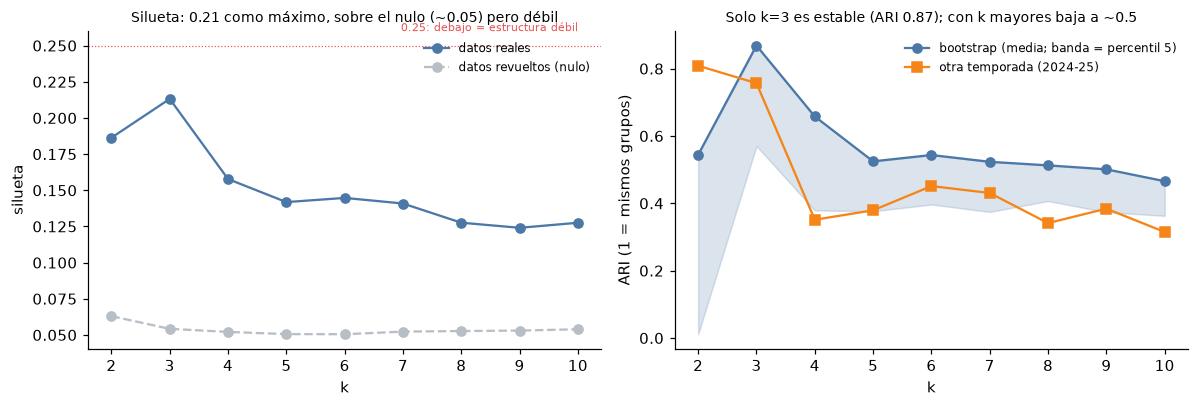

In [3]:
diag = k_diagnostics(z, KS, n_boot=100, n_null=20)
diag["cross_season_ari"] = [cross_season_ari(z_prev, z, k) for k in KS]
print(diag.to_string(index=False))

best = diag.loc[diag["ari_mean"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(diag["k"], diag["silhouette"], marker="o", color="#4C78A8", label="datos reales")
ax.plot(
    diag["k"],
    diag["null_silhouette"],
    marker="o",
    ls="--",
    color="#B8BEC6",
    label="datos revueltos (nulo)",
)
ax.axhline(0.25, color="#E45756", lw=0.8, ls=":")
ax.text(10, 0.26, "0.25: debajo = estructura débil", ha="right", fontsize=7, color="#E45756")
ax.set_xlabel("k")
ax.set_ylabel("silueta")
ax.set_title(
    f"Silueta: {diag['silhouette'].max():.2f} como máximo, sobre el nulo (~{diag['null_silhouette'].mean():.2f}) "
    "pero débil",
    fontsize=9,
)
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.fill_between(diag["k"], diag["ari_p05"], diag["ari_mean"], color="#4C78A8", alpha=0.2)
ax.plot(
    diag["k"],
    diag["ari_mean"],
    marker="o",
    color="#4C78A8",
    label="bootstrap (media; banda = percentil 5)",
)
ax.plot(
    diag["k"],
    diag["cross_season_ari"],
    marker="s",
    color="#F58518",
    label=f"otra temporada ({PREVIOUS})",
)
ax.set_xlabel("k")
ax.set_ylabel("ARI (1 = mismos grupos)")
ax.set_title(
    f"Solo k={int(best['k'])} es estable (ARI {best['ari_mean']:.2f}); con k mayores baja a ~0.5",
    fontsize=9,
)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** La silueta supera al nulo (~0.05) en todos los k, pero nunca pasa de ~0.21, por debajo de 0.25, el límite habitual de "estructura débil". Hay *algo* (las variables se mueven juntas: los pívots rebotean y taponan, los creadores asisten y pierden balones), pero no hay islas. Solo **k = 3** es estable al remuestrear (ARI ~0.87) y razonablemente estable entre temporadas (~0.76). Desde k = 4 baja a ~0.5 y ~0.35-0.45: son cortes arbitrarios de un continuo.

**Nota de método.** El nulo (columnas barajadas) responde a "¿las variables están correlacionadas entre sí?", no a "¿hay islas?". Superarlo es necesario, no suficiente.

## 3. Los tres grupos estables (k = 3)

In [4]:
labels = relabel_by_size(fit_kmeans(z, 3).labels_)
prof = cluster_profile(z, labels)
sizes = prof.pop("size")
print(prof.round(2).to_string())
for g in range(3):
    print(
        f"Grupo {g + 1} ({sizes[g]}):",
        ", ".join(now.loc[labels == g].nlargest(8, "minutes")["player"]),
    )
for name in [
    "Nikola Jokić",
    "Cade Cunningham",
    "Victor Wembanyama",
    "Giannis Antetokounmpo",
    "Onyeka Okongwu",
]:
    print(f"{name}: Grupo {int(labels[(now['player'] == name).to_numpy()][0]) + 1}")

   fga100  fg3a100  fta100  oreb100  dreb100  ast100  tov100  stl100  blk100  pf100  share_ra  share_paint  share_mid  share_corner3  usg_pct  ts_pct
0  -0.530    0.220  -0.640   -0.230   -0.340  -0.440  -0.620   0.150  -0.140  0.120    -0.280       -0.540     -0.370          0.820   -0.610  -0.250
1   0.880    0.330   0.660   -0.450   -0.090   0.720   0.790  -0.050  -0.310 -0.470    -0.350        0.420      0.700         -0.570    0.920  -0.150
2  -0.760   -1.510   0.150    1.830    1.220  -0.590  -0.250  -0.310   1.220  0.880     1.720        0.480     -0.740         -0.930   -0.600   1.110
Grupo 1 (125): Toumani Camara, Jabari Smith Jr., Mikal Bridges, Dyson Daniels, Donte DiVincenzo, Jaden McDaniels, Onyeka Okongwu, Collin Gillespie
Grupo 2 (111): Amen Thompson, Kevin Durant, Desmond Bane, Scottie Barnes, Tyrese Maxey, Jamal Murray, Derrick White, VJ Edgecombe
Grupo 3 (43): Rudy Gobert, Karl-Anthony Towns, Wendell Carter Jr., Donovan Clingan, Evan Mobley, Derik Queen, Chet Holmgren

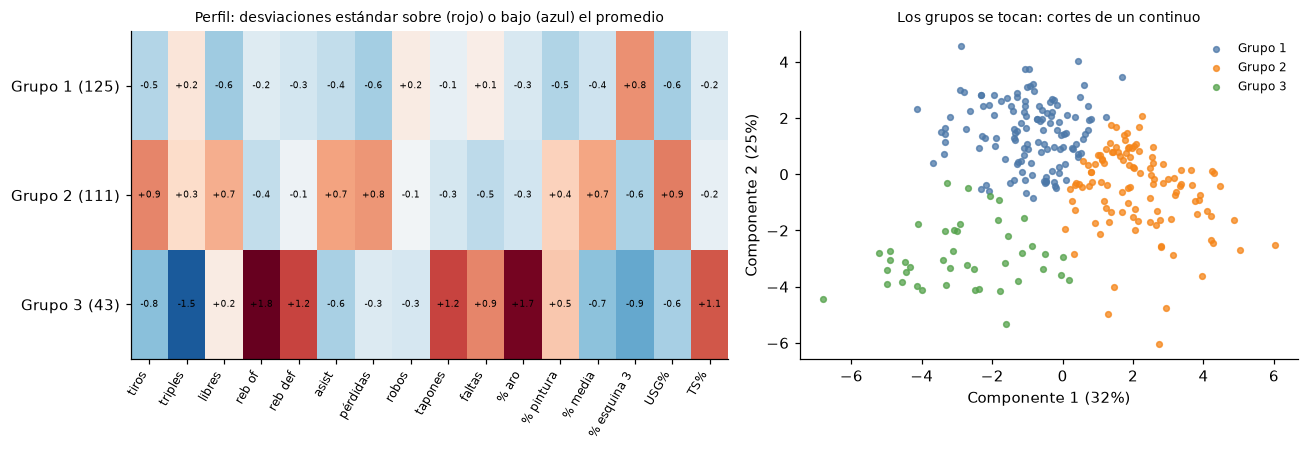

In [5]:
short = {
    "fga100": "tiros",
    "fg3a100": "triples",
    "fta100": "libres",
    "oreb100": "reb of",
    "dreb100": "reb def",
    "ast100": "asist",
    "tov100": "pérdidas",
    "stl100": "robos",
    "blk100": "tapones",
    "pf100": "faltas",
    "share_ra": "% aro",
    "share_paint": "% pintura",
    "share_mid": "% media",
    "share_corner3": "% esquina 3",
    "usg_pct": "USG%",
    "ts_pct": "TS%",
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax1.imshow(prof.to_numpy(), cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
ax1.set_xticks(
    range(prof.shape[1]), [short[c] for c in prof.columns], rotation=60, ha="right", fontsize=8
)
ax1.set_yticks(range(3), [f"Grupo {g + 1} ({sizes[g]})" for g in range(3)])
for i in range(prof.shape[0]):
    for j in range(prof.shape[1]):
        ax1.text(j, i, f"{prof.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=6)
ax1.set_title("Perfil: desviaciones estándar sobre (rojo) o bajo (azul) el promedio", fontsize=9)
colors = ["#4C78A8", "#F58518", "#54A24B"]
for g in range(3):
    m = labels == g
    ax2.scatter(
        coords.loc[m, "PC1"],
        coords.loc[m, "PC2"],
        s=14,
        color=colors[g],
        alpha=0.75,
        label=f"Grupo {g + 1}",
    )
ax2.set_xlabel(f"Componente 1 ({explained[0]:.0%})")
ax2.set_ylabel(f"Componente 2 ({explained[1]:.0%})")
ax2.set_title("Los grupos se tocan: cortes de un continuo", fontsize=9)
ax2.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Los tres grupos** (nombres míos, tras leer los perfiles):
- **Grupo 1 (~125), jugadores de rol perimetrales:** poco uso, tiran sobre todo triples de esquina, pocas pérdidas y pocos libres (p. ej. Camara, Bridges, DiVincenzo, McDaniels). No es solo perimetrales: también cae aquí algún pívot de poco uso como Okongwu.
- **Grupo 2 (~111), creadores y anotadores:** alto uso, más tiros, libres, asistencias y pérdidas, más media distancia (p. ej. Durant, Maxey, Murray, Barnes).
- **Grupo 3 (~43), pívots cerca del aro:** rebotes ofensivos y defensivos, tapones y tiros desde el aro, casi sin triples, TS% alto (p. ej. Gobert, Towns, Mobley, Duren).

**Lo que esto NO dice:** que haya tres "tipos" distintos de jugador: el mapa muestra que los grupos se tocan. Y el grupo 2 mezcla jugadores muy distintos: Jokić, Cunningham, Wembanyama y Giannis caen todos ahí junto a Durant o Maxey, aunque (sección 5) Wembanyama y Giannis son los más atípicos de la liga.

## 4. ¿Y si elijo otras variables?

Si el agrupamiento cambia mucho al quitar un bloque de variables, depende de una decisión mía y no de los datos.

solo por 100 posesiones   0.430
solo zonas + uso + TS%    0.657
sin zonas de tiro         0.584
sin faltas ni pérdidas    0.870


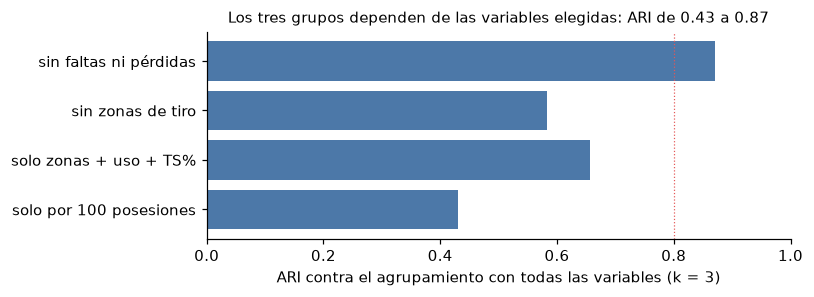

In [6]:
agree = feature_set_agreement(z, FEATURE_SUBSETS, k=3)
print(agree.rename("ARI contra el completo").to_string())
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh(agree.index, agree.values, color="#4C78A8")
ax.set_xlim(0, 1)
ax.axvline(0.8, color="#E45756", ls=":", lw=0.8)
ax.set_xlabel("ARI contra el agrupamiento con todas las variables (k = 3)")
ax.set_title(
    f"Los tres grupos dependen de las variables elegidas: ARI de {agree.min():.2f} a {agree.max():.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

**Lectura.** Con solo las variables por 100 posesiones el agrupamiento coincide apenas a ARI ~0.43; sin las zonas de tiro, ~0.58; y solo quitando faltas y pérdidas se conserva (~0.87). Los tres grupos **no son robustos a la elección de variables**: la división en grandes y perimetrales sí aguanta, pero dónde cae la frontera entre "rol" y "creador" depende de qué medimos. Esto es importante: es la razón para no vender "los 3 roles de la NBA" como un hecho.

## 5. Jugadores parecidos

La distancia entre perfiles estandarizados es más informativa que el número de grupo, que es solo una etiqueta de un corte.

In [7]:
for name in ["Nikola Jokić", "Rudy Gobert", "Mikal Bridges"]:
    near = nearest_players(z, now["player"], name, n=5)
    print(
        f"{name}:",
        ", ".join(f"{p} ({d:.1f})" for p, d in zip(near["player"], near["distance"], strict=True)),
    )

Nikola Jokić: Jalen Johnson (3.4), Alperen Sengun (4.2), Josh Giddey (4.2), Cade Cunningham (4.3), Deni Avdija (4.4)
Rudy Gobert: Moussa Diabaté (2.3), Daniel Gafford (2.3), Luke Kornet (2.4), Mark Williams (2.9), Adem Bona (3.1)
Mikal Bridges: Tristan da Silva (1.9), Devin Vassell (2.2), Andrew Wiggins (2.2), Tobias Harris (2.2), Miles McBride (2.3)


In [8]:
from scipy.spatial.distance import cdist

d = cdist(z.to_numpy(), z.to_numpy())
np.fill_diagonal(d, np.inf)
nn = pd.Series(d.min(axis=1), index=now["player"])
rank = int((nn > nn["Nikola Jokić"]).sum()) + 1
print(
    f"Distancia al vecino más cercano: mediana de la liga {nn.median():.2f}; "
    f"Jokić {nn['Nikola Jokić']:.2f} (puesto {rank} de {len(nn)} en aislamiento)"
)
print("Los 5 más aislados:", ", ".join(f"{p} ({v:.1f})" for p, v in nn.nlargest(5).items()))

Distancia al vecino más cercano: mediana de la liga 2.06; Jokić 3.40 (puesto 11 de 279 en aislamiento)
Los 5 más aislados: Victor Wembanyama (5.1), Giannis Antetokounmpo (4.7), Mitchell Robinson (4.0), DeMar DeRozan (3.7), Karl-Anthony Towns (3.7)


Jokić está a 3.4 de su vecino más cercano, frente a una mediana de 2.1 en la liga; Wembanyama (5.1) y Giannis (4.7) están aún más aislados. Un jugador sin vecinos cercanos no encaja bien en ningún grupo, y la etiqueta de k-means lo esconde dentro de uno. Por eso conviene mirar distancias y no solo el número de grupo.

## 6. Resultado vs. hipótesis

No hubo hipótesis previa. Contra la referencia "sin estructura":

| Pregunta | Resultado 2025-26 | Veredicto |
|---|---|---|
| D. ¿Grupos naturales? | Silueta máx. 0.21 (nulo 0.05), por debajo de 0.25 | Estructura débil: hay un continuo con algo de forma |
| D. ¿Cuántos? | k=3 es el único estable (ARI 0.87 bootstrap, 0.76 otra temporada) | 3 grupos gruesos; k ≥ 4 no es estable |
| D. ¿Se parecen a las 5 posiciones? | Con k=5 el ARI de estabilidad baja a ~0.5 | No: las 5 posiciones no se recuperan de las estadísticas |
| Robustez | ARI 0.43-0.87 según las variables | Los 3 grupos dependen de mis decisiones |

**Qué mejorar (no hecho):** agrupación jerárquica o mezclas gaussianas (pertenencia parcial), reducir variables correlacionadas antes de agrupar, datos de tracking (defensa, pases) que separen mejor a los creadores, y más temporadas.

## 7. Tus ejercicios

1. **Predice y mide.** Cambia `min_minutes` a 1500 en `season_features`. Antes de correr, escribe si esperas que k=3 siga siendo el más estable, y si la silueta suba o baje. Luego mide.
2. **Quita algo que importa.** Elimina `usg_pct` y `ts_pct` de las variables y repite el ARI contra el agrupamiento completo. Predice si el grupo de creadores (Grupo 2) sobrevive y explica por qué sí o no.